In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/data_folder/Diabetes-Classification.csv')

In [3]:
df.head()

,Age,Gender,BMI,Blood Pressure,FBS,HbA1c,Family History of Diabetes,Smoking,Diet,Exercise,Diagnosis
0,45,Male,25.0,Normal,100,5.7,No,No,Healthy,Regular,No
1,55,Female,30.0,High,120,6.4,Yes,Yes,Poor,No,Yes
2,65,Male,35.0,High,140,7.1,Yes,Yes,Poor,No,Yes
3,75,Female,40.0,High,160,7.8,Yes,Yes,Poor,No,Yes
4,40,Male,20.0,Normal,80,5.0,No,No,Healthy,NaN,No


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         128 non-null    int64  
 1   Gender                      128 non-null    object 
 2   BMI                         125 non-null    float64
 3   Blood Pressure              128 non-null    object 
 4   FBS                         128 non-null    int64  
 5   HbA1c                       128 non-null    float64
 6   Family History of Diabetes  126 non-null    object 
 7   Smoking                     126 non-null    object 
 8   Diet                        126 non-null    object 
 9   Exercise                    127 non-null    object 
 10  Diagnosis                   128 non-null    object 
dtypes: float64(2), int64(2), object(7)
memory usage: 11.1+ KB


In [5]:
df.isnull().sum()

,0
Age,0
Gender,0
BMI,3
Blood Pressure,0
FBS,0
HbA1c,0
Family History of Diabetes,2
Smoking,2
Diet,2
Exercise,1


In [6]:
df=df.dropna()

In [7]:
df.isnull().sum()

,0
Age,0
Gender,0
BMI,0
Blood Pressure,0
FBS,0
HbA1c,0
Family History of Diabetes,0
Smoking,0
Diet,0
Exercise,0


In [8]:
df.head()

,Age,Gender,BMI,Blood Pressure,FBS,HbA1c,Family History of Diabetes,Smoking,Diet,Exercise,Diagnosis
0,45,Male,25.0,Normal,100,5.7,No,No,Healthy,Regular,No
1,55,Female,30.0,High,120,6.4,Yes,Yes,Poor,No,Yes
2,65,Male,35.0,High,140,7.1,Yes,Yes,Poor,No,Yes
3,75,Female,40.0,High,160,7.8,Yes,Yes,Poor,No,Yes
5,50,Female,25.0,Normal,100,5.7,No,No,Healthy,Regular,No


In [9]:
#Problems with categorical values in columns:
#1: these are in string format
#2: categorical variables confuses

#label encoding
from sklearn.preprocessing import LabelEncoder
cat_col=['Diagnosis']

le=LabelEncoder()

for col in cat_col:
    df[col]=le.fit_transform(df[col])

df.head()

,Age,Gender,BMI,Blood Pressure,FBS,HbA1c,Family History of Diabetes,Smoking,Diet,Exercise,Diagnosis
0,45,Male,25.0,Normal,100,5.7,No,No,Healthy,Regular,0
1,55,Female,30.0,High,120,6.4,Yes,Yes,Poor,No,1
2,65,Male,35.0,High,140,7.1,Yes,Yes,Poor,No,1
3,75,Female,40.0,High,160,7.8,Yes,Yes,Poor,No,1
5,50,Female,25.0,Normal,100,5.7,No,No,Healthy,Regular,0


In [10]:
#one hot encoding
one_encoded= pd.get_dummies(df,columns=['Gender'])
one_encoded.head()

,Age,BMI,Blood Pressure,FBS,HbA1c,Family History of Diabetes,Smoking,Diet,Exercise,Diagnosis,Gender_Female,Gender_Male
0,45,25.0,Normal,100,5.7,No,No,Healthy,Regular,0,False,True
1,55,30.0,High,120,6.4,Yes,Yes,Poor,No,1,True,False
2,65,35.0,High,140,7.1,Yes,Yes,Poor,No,1,False,True
3,75,40.0,High,160,7.8,Yes,Yes,Poor,No,1,True,False
5,50,25.0,Normal,100,5.7,No,No,Healthy,Regular,0,True,False


In [11]:
#how to choose either label encoding or onehot encoding:
#it depends on the type of categorical variable:

#label encoding: when values in features are ordinal: order Ex: Education - Bachelors>Masters>Doctorate
#Onehotending: When categories are not in order (Nominal Values):  Gender- Male, Female, Smoking etc

#we are applying one hot encoding

cat_col=['Gender','Exercise','Blood Pressure', 'Family History of Diabetes', 'Smoking', 'Diet']

one_encoded= pd.get_dummies(df,columns=cat_col)

one_encoded.head()

,Age,BMI,FBS,HbA1c,Diagnosis,Gender_Female,Gender_Male,Exercise_No,Exercise_Regular,Blood Pressure_High,Blood Pressure_Low,Blood Pressure_Normal,Family History of Diabetes_No,Family History of Diabetes_Yes,Smoking_No,Smoking_Yes,Diet_Healthy,Diet_Poor
0,45,25.0,100,5.7,0,False,True,False,True,False,False,True,True,False,True,False,True,False
1,55,30.0,120,6.4,1,True,False,True,False,True,False,False,False,True,False,True,False,True
2,65,35.0,140,7.1,1,False,True,True,False,True,False,False,False,True,False,True,False,True
3,75,40.0,160,7.8,1,True,False,True,False,True,False,False,False,True,False,True,False,True
5,50,25.0,100,5.7,0,True,False,False,True,False,False,True,True,False,True,False,True,False


In [12]:
#label encoding the one hot encoded columns to convert all the string values in newly generated columns to integers
cat_col=[ 'Gender_Female',
       'Gender_Male', 'Exercise_No', 'Exercise_Regular', 'Blood Pressure_High',
       'Blood Pressure_Low', 'Blood Pressure_Normal',
       'Family History of Diabetes_No', 'Family History of Diabetes_Yes',
       'Smoking_No', 'Smoking_Yes', 'Diet_Healthy', 'Diet_Poor']
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for col in cat_col:
    one_encoded[col]=le.fit_transform(one_encoded[col])

In [13]:
one_encoded.head()

,Age,BMI,FBS,HbA1c,Diagnosis,Gender_Female,Gender_Male,Exercise_No,Exercise_Regular,Blood Pressure_High,Blood Pressure_Low,Blood Pressure_Normal,Family History of Diabetes_No,Family History of Diabetes_Yes,Smoking_No,Smoking_Yes,Diet_Healthy,Diet_Poor
0,45,25.0,100,5.7,0,0,1,0,1,0,0,1,1,0,1,0,1,0
1,55,30.0,120,6.4,1,1,0,1,0,1,0,0,0,1,0,1,0,1
2,65,35.0,140,7.1,1,0,1,1,0,1,0,0,0,1,0,1,0,1
3,75,40.0,160,7.8,1,1,0,1,0,1,0,0,0,1,0,1,0,1
5,50,25.0,100,5.7,0,1,0,0,1,0,0,1,1,0,1,0,1,0


In [14]:
#Assignment:

#Perform -
#Descriptive analysis
#Exploratory data analysis
#here.

#we will discuss about these in the mentoring session


# Descriptive Analysis

# Number of rows and columns
print("Dataset shape:", df.shape)

# Summary statistics
display(df.describe(include='all'))

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count how many patients belong to each diagnosis class
print("\nDiagnosis distribution:")
print(df['Diagnosis'].value_counts())

# Average numerical values for each diagnosis class
display(df.groupby('Diagnosis')[['Age', 'BMI', 'FBS', 'HbA1c']].mean().round(2))


Dataset shape: (118, 11)


,Age,Gender,BMI,Blood Pressure,FBS,HbA1c,Family History of Diabetes,Smoking,Diet,Exercise,Diagnosis
count,118.00000,118,118.000000,118,118.000000,118.000000,118,118,118,118,118.000000
unique,NaN,2,NaN,3,NaN,NaN,2,2,2,2,NaN
top,NaN,Male,NaN,High,NaN,NaN,No,Yes,Poor,No,NaN
freq,NaN,61,NaN,73,NaN,NaN,71,74,74,74,NaN
mean,43.09322,NaN,36.220339,NaN,163.559322,7.924576,NaN,NaN,NaN,NaN,0.254237
std,21.46792,NaN,16.542685,NaN,62.244698,2.178564,NaN,NaN,NaN,NaN,0.437288
min,12.00000,NaN,10.000000,NaN,80.000000,5.000000,NaN,NaN,NaN,NaN,0.000000
25%,28.00000,NaN,24.000000,NaN,120.000000,6.400000,NaN,NaN,NaN,NaN,0.000000
50%,40.00000,NaN,34.000000,NaN,160.000000,7.800000,NaN,NaN,NaN,NaN,0.000000
75%,56.50000,NaN,48.500000,NaN,220.000000,9.900000,NaN,NaN,NaN,NaN,0.750000



Missing values:
Age                           0
Gender                        0
BMI                           0
Blood Pressure                0
FBS                           0
HbA1c                         0
Family History of Diabetes    0
Smoking                       0
Diet                          0
Exercise                      0
Diagnosis                     0
dtype: int64

Diagnosis distribution:
Diagnosis
0    88
1    30
Name: count, dtype: int64


,Age,BMI,FBS,HbA1c
Diagnosis,,,,
0,45.34,39.28,175.68,8.35
1,36.50,27.23,128.00,6.68


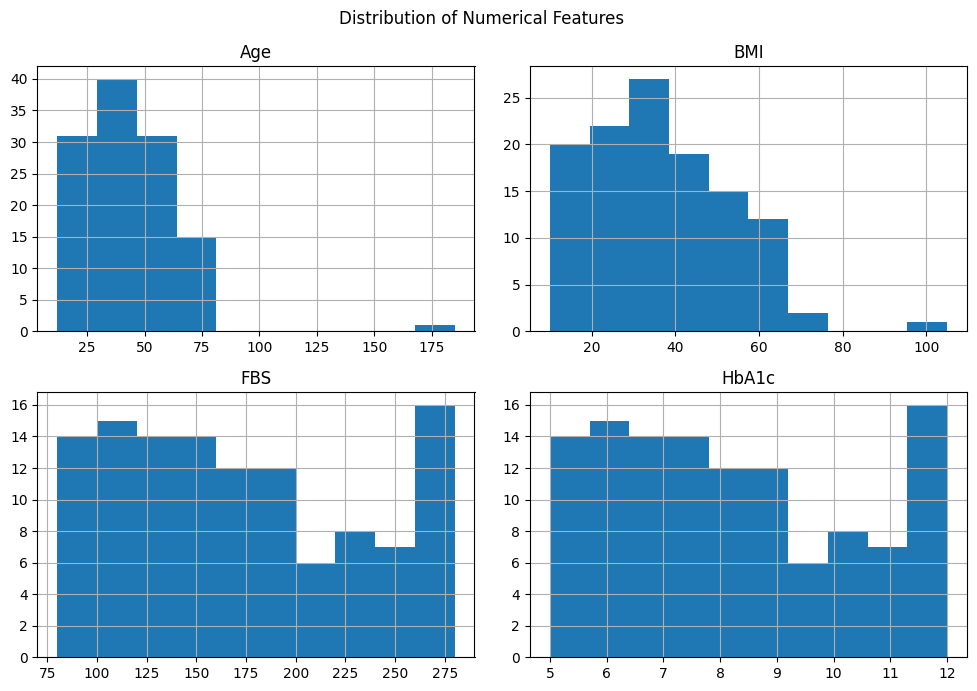

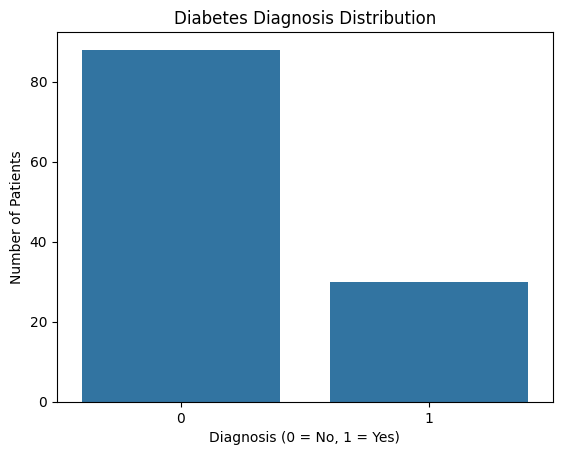

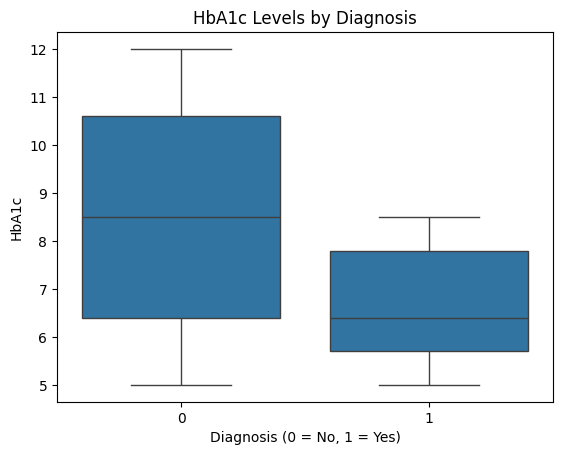

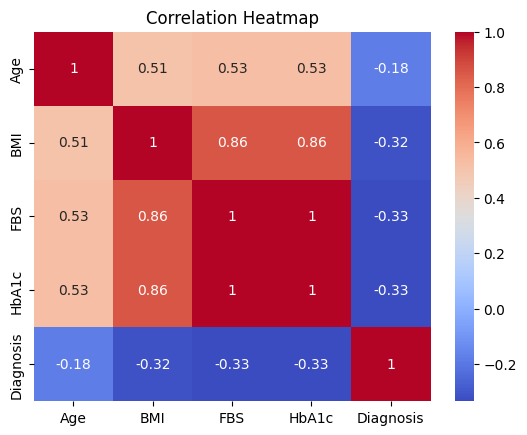

In [15]:
#Exploratory data analysis
#here.


# Exploratory Data Analysis (EDA)

# 1. Distribution of numerical features
df[['Age', 'BMI', 'FBS', 'HbA1c']].hist(
    figsize=(10, 7),
    bins=10
)
plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

# 2. Number of patients in each diagnosis class
sns.countplot(data=df, x='Diagnosis')
plt.title('Diabetes Diagnosis Distribution')
plt.xlabel('Diagnosis (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.show()

# 3. Compare HbA1c levels across diagnosis classes
sns.boxplot(data=df, x='Diagnosis', y='HbA1c')
plt.title('HbA1c Levels by Diagnosis')
plt.xlabel('Diagnosis (0 = No, 1 = Yes)')
plt.ylabel('HbA1c')
plt.show()

# 4. Correlation between numerical features
sns.heatmap(
    df[['Age', 'BMI', 'FBS', 'HbA1c', 'Diagnosis']].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.show()

In [16]:
#Feature Selection: Removing irrelevant features which does not contribute towards the label(Diagnosis)
#defining feature selection model
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=5)

In [17]:
#splitting label and features
x=one_encoded.drop('Diagnosis', axis=1)
y=one_encoded['Diagnosis']

In [18]:
#applying feature selection
x_selected=selector.fit_transform(x,y)
selected_features=x.columns[selector.get_support()]
print(selected_features)

Index(['Exercise_Regular', 'Smoking_No', 'Smoking_Yes', 'Diet_Healthy',
       'Diet_Poor'],
      dtype='object')


In [19]:
#created df with selected features
x1=one_encoded[selected_features]

In [20]:
#train test split
from sklearn.model_selection import train_test_split

#for all features
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.4,random_state=10)

In [21]:
#for selected features
x1_train, x1_test, y_train, y_test=train_test_split(x1,y,test_size=0.4,random_state=10)

In [22]:
#building knn models
from sklearn.neighbors import KNeighborsClassifier

knn=KNeighborsClassifier(n_neighbors=5)
knn_selected=KNeighborsClassifier(n_neighbors=5)

In [23]:
#training models
#all features
knn.fit(x_train,y_train)
y_pred_knn=knn.predict(x_test)


#selcted features
knn_selected.fit(x1_train,y_train)
y_pred_knn1=knn_selected.predict(x1_test)

In [24]:
#classification report

from sklearn.metrics import classification_report

print("nKNN Performance:")
print(classification_report(y_test, y_pred_knn))

print("nKNN_Selected Performance:")
print(classification_report(y_test, y_pred_knn1))

nKNN Performance:
              precision    recall  f1-score   support

           0       0.82      0.69      0.75        39
           1       0.20      0.33      0.25         9

    accuracy                           0.62        48
   macro avg       0.51      0.51      0.50        48
weighted avg       0.70      0.62      0.66        48

nKNN_Selected Performance:
              precision    recall  f1-score   support

           0       1.00      0.54      0.70        39
           1       0.33      1.00      0.50         9

    accuracy                           0.62        48
   macro avg       0.67      0.77      0.60        48
weighted avg       0.88      0.62      0.66        48



In [25]:
#building svm models
from sklearn.svm import SVC

svm=SVC(kernel='rbf', probability=True,random_state=10 )
svm_selected=SVC(kernel='rbf', probability=True,random_state=10 )

In [26]:
#training models
#all features
svm.fit(x_train,y_train)
y_pred_svm=svm.predict(x_test)


#selcted features
svm_selected.fit(x1_train,y_train)
y_pred_svm1=svm_selected.predict(x1_test)

In [27]:
#classification report

from sklearn.metrics import classification_report

print("SVM Performance:")
print(classification_report(y_test, y_pred_svm))

print("nSVM_Selected Performance:")
print(classification_report(y_test, y_pred_svm1))

SVM Performance:
              precision    recall  f1-score   support

           0       0.81      1.00      0.90        39
           1       0.00      0.00      0.00         9

    accuracy                           0.81        48
   macro avg       0.41      0.50      0.45        48
weighted avg       0.66      0.81      0.73        48

nSVM_Selected Performance:
              precision    recall  f1-score   support

           0       0.81      1.00      0.90        39
           1       0.00      0.00      0.00         9

    accuracy                           0.81        48
   macro avg       0.41      0.50      0.45        48
weighted avg       0.66      0.81      0.73        48



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

<Axes: >

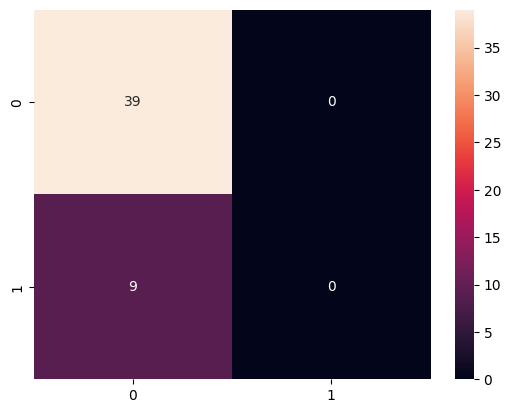

In [28]:
#confusion: it show labelwise performance of the model

from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_test,y_pred_svm)
sns.heatmap(cm,annot=True)

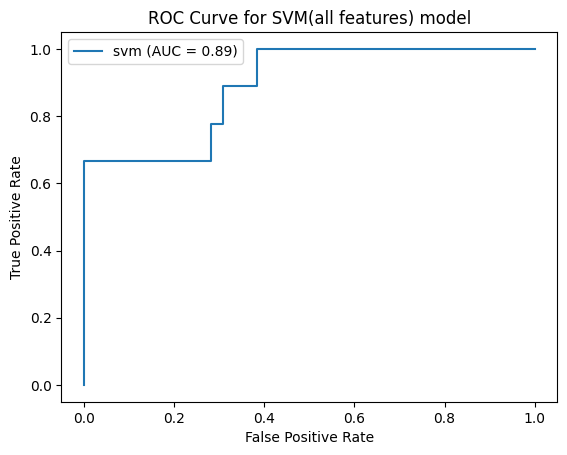

In [29]:
#plot ROC curve for svm all features model
from sklearn.metrics import roc_auc_score, roc_curve

y_proba = svm.predict_proba(x_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=f'{'svm'} (AUC = {roc_auc_score(y_test, y_proba):.2f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for SVM(all features) model')
plt.legend()
plt.show()

In [30]:
#Assignment:

#1:Plot confusion matrix and ROC curves for other models
#2:Learn more about evaluation metrics sucha as confusion matrix, accuracy, precision, recall, AUC, ROC etc
#3:Compare the performance(accuracy, f1 score etc) of SVM and KNN models we created using graph plots
#4: Re-do the entire analysis with label encoding instead of one hot encoding and notice performance difference

#we will discuss about these in mentoring session

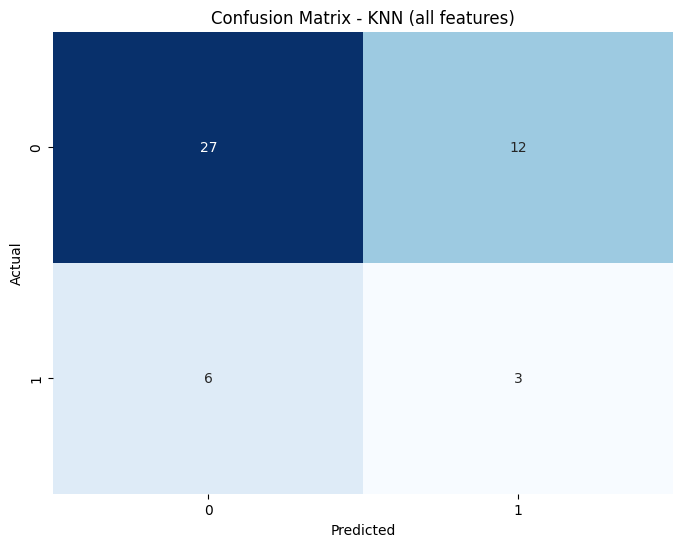

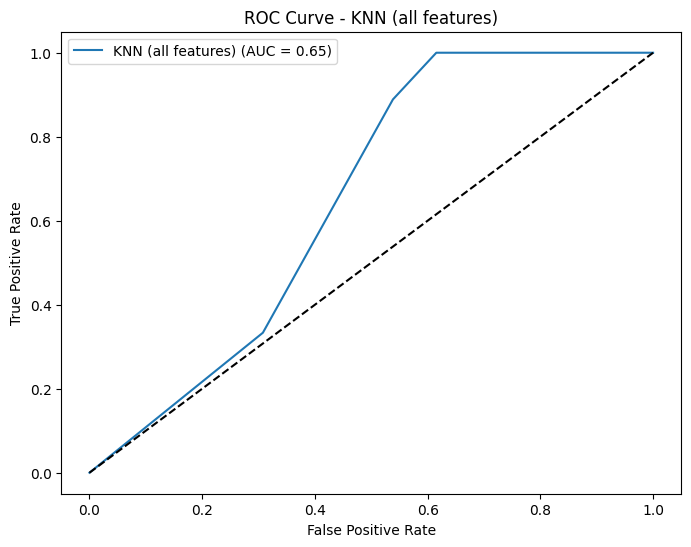

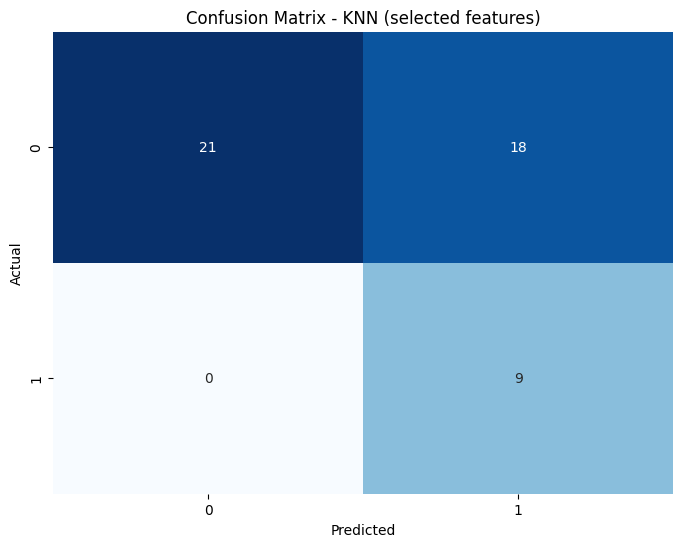

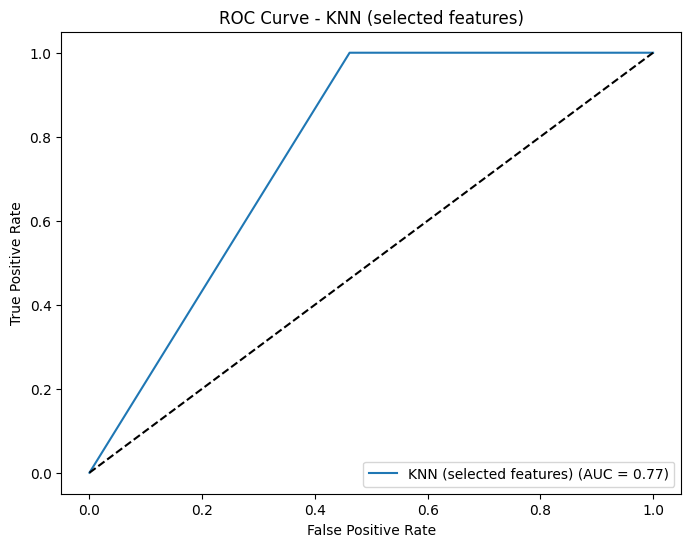

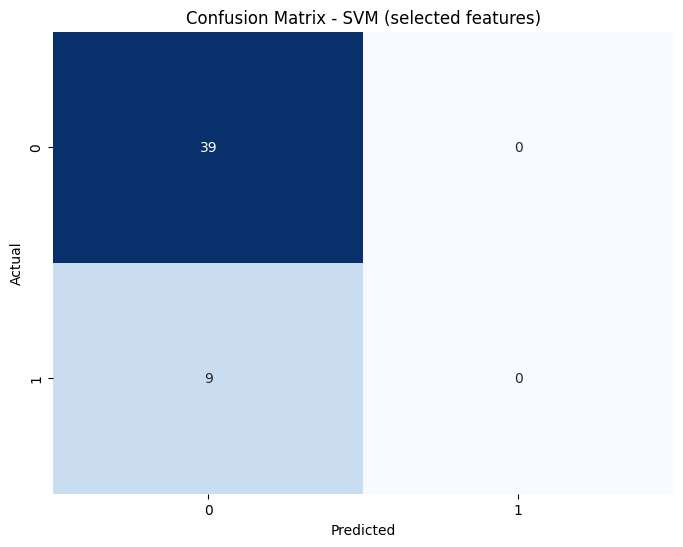

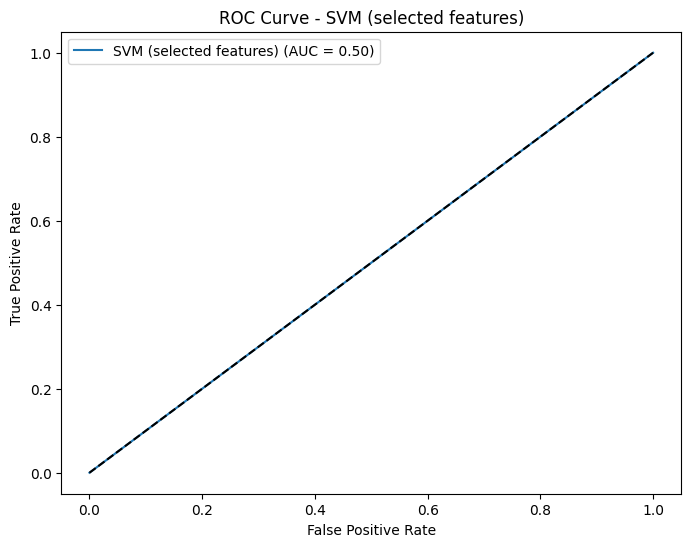

In [31]:
#Plot confusion matrix and ROC curves for other models

models = [("KNN (all features)", knn, x_test, y_pred_knn),
    ("KNN (selected features)", knn_selected, x1_test, y_pred_knn1),
    ("SVM (selected features)", svm_selected, x1_test, y_pred_svm1)]

for name, model, test_data, predictions in models:
  #confusion matrix
  cm = confusion_matrix(y_test, predictions)

  plt.figure(figsize=(8, 6))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
  plt.title(f'Confusion Matrix - {name}')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.show()

  # ROC curve
  y_proba = model.predict_proba(test_data)[:, 1]
  fpr, tpr, _ = roc_curve(y_test, y_proba)

  plt.figure(figsize=(8, 6))
  plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, y_proba):.2f})')
  plt.plot([0, 1], [0, 1], 'k--')
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title(f'ROC Curve - {name}')
  plt.legend()
  plt.show()

In [32]:
#2:Learn more about evaluation metrics sucha as confusion matrix, accuracy, precision, recall, AUC, ROC etc

In [33]:
#3:Compare the performance(accuracy, f1 score etc) of SVM and KNN models we created using graph plots
from sklearn.metrics import accuracy_score, recall_score, f1_score

model_predictions = {"KNN (All Features)": y_pred_knn,
                     "KNN (Selected Features)": y_pred_knn1,
                     "SVM (All Features)": y_pred_svm,
                     "SVM (Selected Features)": y_pred_svm1,
                     }
results = []

for name, predictions in model_predictions.items():
    accuracy = accuracy_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df

,Accuracy,Recall,F1 Score
Model,,,
KNN (All Features),0.6250,0.333333,0.25
KNN (Selected Features),0.6250,1.000000,0.50
SVM (All Features),0.8125,0.000000,0.00
SVM (Selected Features),0.8125,0.000000,0.00


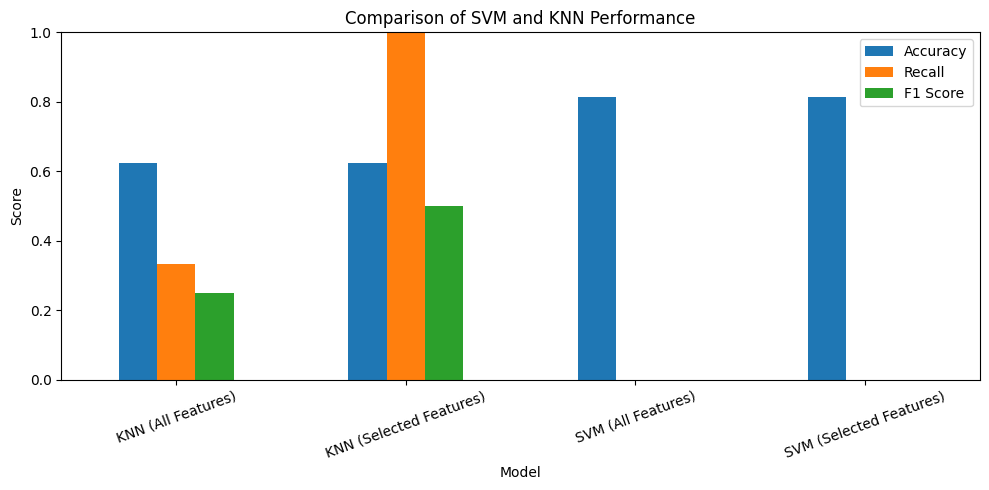

In [34]:
results_df.plot(kind='bar', figsize=(10, 5))
plt.title('Comparison of SVM and KNN Performance')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [37]:
#4: Re-do the entire analysis with label encoding instead of one hot encoding and notice performance difference

#I will be using the original dataset to avoid using the one-hot encoded version
label_encoded_df = df.copy()

categorical_cols = ["Gender", "Exercise", "Blood Pressure", "Family History of Diabetes", "Smoking", "Diet"]

for col in categorical_cols:
    label_encoded_df[col] = LabelEncoder().fit_transform(df[col])

label_encoded_df.head()

,Age,Gender,BMI,Blood Pressure,FBS,HbA1c,Family History of Diabetes,Smoking,Diet,Exercise,Diagnosis
0,45,1,25.0,2,100,5.7,0,0,0,1,0
1,55,0,30.0,0,120,6.4,1,1,1,0,1
2,65,1,35.0,0,140,7.1,1,1,1,0,1
3,75,0,40.0,0,160,7.8,1,1,1,0,1
5,50,0,25.0,2,100,5.7,0,0,0,1,0


In [39]:
#split features and target
x_label_encoded = label_encoded_df.drop("Diagnosis", axis=1)
y_label_encoded = label_encoded_df["Diagnosis"]
x_label_encoded_train, x_label_encoded_test, y_label_encoded_train, y_label_encoded_test = train_test_split(
    x_label_encoded, y_label_encoded, test_size=0.4, random_state=10,
    )

#train KNN and SVM
knn_label_encoded = KNeighborsClassifier(n_neighbors=5)
knn_label_encoded.fit(x_label_encoded_train, y_label_encoded_train)
y_pred_knn_label_encoded = knn_label_encoded.predict(x_label_encoded_test)

svm_label_encoded = SVC(kernel="rbf", probability=True, random_state=10)
svm_label_encoded.fit(x_label_encoded_train, y_label_encoded_train)
y_pred_svm_label_encoded = svm_label_encoded.predict(x_label_encoded_test)

#comparing the results
label_encoded_results = pd.DataFrame({"Model": ["KNN (Label Encoded)", "SVM (Label Encoded)"],
                                      "Accuracy": [accuracy_score(y_label_encoded_test, y_pred_knn_label_encoded),
                                                   accuracy_score(y_label_encoded_test, y_pred_svm_label_encoded)],
                                      "Recall": [recall_score(y_label_encoded_test, y_pred_knn_label_encoded),
                                                recall_score(y_label_encoded_test, y_pred_svm_label_encoded)],
                                      "F1 Score": [f1_score(y_label_encoded_test, y_pred_knn_label_encoded),
                                                 f1_score(y_label_encoded_test, y_pred_svm_label_encoded)],
                                      })

label_encoded_results

,Model,Accuracy,Recall,F1 Score
0,KNN (Label Encoded),0.6250,0.333333,0.25
1,SVM (Label Encoded),0.8125,0.000000,0.00


Both models produced the same accuracy, recall and F1-scores as before, suggesting that changing the encoding method did not affect their performance in this particular experiment.